# NumPy Interview Preparation (Internship Level)

**How to use this notebook**
- Each question is followed by a **professional, interview-ready answer** (say it in your own words) and a **runnable code demo**.
- Run the cells top to bottom. Start with the import cell below.
- Sections: Fundamentals → Creation → Attributes → Reshaping → Indexing → Operations → Statistics → Sorting/Searching → Joining/Splitting → Copy vs View → Random → Linear Algebra → Missing Values → Performance → File I/O → Coding Problems → Tricky Questions → HR/Project Questions → Cheat Sheet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("NumPy version:", np.__version__)

NumPy version: 2.5.2


---
## 1. Fundamentals (Theory)

Q1 : <B>What is NumPy, and why do we use it instead of ordinary Python lists when working with numerical data?

**Answer:**

**NumPy (Numerical Python)** is an open-source library that provides a fast, multi-dimensional array object called `ndarray`, along with a large collection of mathematical functions that operate on it.

We prefer it over Python lists for numerical work because:

1. **Speed** - operations run in pre-compiled C code, not in the slow Python interpreter loop.
2. **Memory efficiency** - an array stores raw, fixed-type values side by side in one contiguous block; a list stores pointers to separate Python objects.
3. **Vectorization** - `arr * 2` works on the whole array at once; with a list we need a loop (and `list * 2` just repeats the list!).
4. **Broadcasting** - arrays of different shapes can be combined without manual loops.
5. **Rich functionality** - statistics, linear algebra, random numbers, sorting, set operations, FFT, etc.
6. **Ecosystem** - Pandas, Matplotlib, SciPy, scikit-learn, TensorFlow and PyTorch are all built on NumPy-style arrays.

In [2]:
import sys, time
n = 1_000_000
py_list = list(range(n))
np_arr = np.arange(n)

t = time.perf_counter(); _ = [x * 2 for x in py_list]; list_time = time.perf_counter() - t
t = time.perf_counter(); _ = np_arr * 2;               np_time = time.perf_counter() - t

print(f"List comprehension : {list_time:.4f} s")
print(f"NumPy vectorized   : {np_time:.4f} s   (~{list_time/np_time:.0f}x faster)")

list_mem = sys.getsizeof(py_list) + sum(sys.getsizeof(x) for x in py_list)
print(f"\nList memory  : {list_mem/1e6:.1f} MB")
print(f"Array memory : {np_arr.nbytes/1e6:.1f} MB")

List comprehension : 0.0346 s
NumPy vectorized   : 0.0097 s   (~4x faster)

List memory  : 36.0 MB
Array memory : 8.0 MB


Q2 : <B>What is an `ndarray`? What are its key characteristics?

**Answer:**

`ndarray` (N-dimensional array) is NumPy's core data structure - a **homogeneous, fixed-size, grid of values** indexed by a tuple of integers.

Key characteristics:
- **Homogeneous**: every element has the same `dtype`.
- **Fixed size**: size is set at creation; resizing creates a new array.
- **N-dimensional**: 1D (vector), 2D (matrix), 3D+ (tensor).
- **Contiguous memory** (usually), which enables speed and CPU-cache friendliness.
- Described by metadata: `shape`, `ndim`, `size`, `dtype`, `strides`.

In [3]:
a = np.array([[1, 2, 3], [4, 5, 6]])
print(type(a))
print("shape  :", a.shape)
print("ndim   :", a.ndim)
print("size   :", a.size)
print("dtype  :", a.dtype)
print("strides:", a.strides)

<class 'numpy.ndarray'>
shape  : (2, 3)
ndim   : 2
size   : 6
dtype  : int64
strides: (24, 8)


Q3 : <B>What are the advantages and limitations of NumPy?

**Answer:**

**Advantages:** fast, memory-efficient, vectorized and broadcast operations, concise code, huge function library, foundation of the Python data-science stack.

**Limitations:**
- Elements must be of **one dtype** (mixed data forces upcasting).
- **Fixed size** - appending/inserting copies the whole array.
- Entire array must fit in **RAM** (no out-of-core support).
- Runs on **CPU only** (no GPU) - use CuPy / PyTorch / JAX for that.
- Not ideal for **labelled / tabular / mixed-type data** - Pandas is better.
- No built-in handling of missing data beyond `np.nan` (floats only).

Q4 : <B>How do you install and import NumPy? Why do we write `import numpy as np`?

**Answer:**

Install with `pip install numpy` (or `conda install numpy`). Import with `import numpy as np`.

`np` is just a community-wide **convention (alias)**; it saves typing and makes code instantly readable to other developers. To check the installed version use `np.__version__`.

In [4]:
import numpy as np
print(np.__version__)

2.5.4


Q5 : <B>Explain vector, matrix and tensor in NumPy terms.

**Answer:**

| Term | Dimensions | NumPy example |
|---|---|---|
| Scalar | 0D | `np.array(5)` |
| **Vector** | 1D | `np.array([1, 2, 3])` |
| **Matrix** | 2D | `np.array([[1, 2, 3], [4, 5, 6]])` |
| **Tensor** | 3D or more | `np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])` |

`ndim` tells how many dimensions an array has; `shape` tells the length along each dimension.

In [5]:
scalar = np.array(5)
vector = np.array([1, 2, 3])
matrix = np.array([[1, 2, 3], [4, 5, 6]])
tensor = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])

for name, x in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("tensor", tensor)]:
    print(f"{name:7s} ndim={x.ndim} shape={x.shape}")

scalar  ndim=0 shape=()
vector  ndim=1 shape=(3,)
matrix  ndim=2 shape=(2, 3)
tensor  ndim=3 shape=(2, 2, 2)


Q6 : <B>What is the difference between a Python list and a NumPy array?

**Answer:**

| Feature | Python list | NumPy array |
|---|---|---|
| Data types | Mixed allowed | Single dtype (homogeneous) |
| Memory | Pointers to objects (heavy) | Raw values, contiguous (light) |
| Speed | Slower (Python loops) | Much faster (C, vectorized) |
| `*`, `+` operator | Repeat / concatenate | Element-wise math |
| Dimensions | Nested lists, manual | Native N-D with `shape` |
| Built-in math | None | Hundreds of functions |

In [6]:
py_list = [10, 20, 30]
np_array = np.array([10, 20, 30])

print("list  * 2 :", py_list * 2)     # repeats the list
print("array * 2 :", np_array * 2)    # element-wise

print("list  + list :", py_list + [1, 2, 3])               # concatenation
print("array + array:", np_array + np.array([1, 2, 3]))    # element-wise addition

list  * 2 : [10, 20, 30, 10, 20, 30]
array * 2 : [20 40 60]
list  + list : [10, 20, 30, 1, 2, 3]
array + array: [11 22 33]


Q7 : <B>What is vectorization? Why is it important?

**Answer:**

**Vectorization** means applying an operation to an entire array without writing an explicit Python `for` loop. The loop still happens, but inside optimized, pre-compiled C code (often using SIMD CPU instructions).

Importance: it makes code **shorter, more readable and dramatically faster** - the golden rule in NumPy is *"avoid Python loops over arrays."*

In [7]:
prices = np.array([100, 250, 400, 999])

# Loop style (slow, verbose)
with_gst_loop = []
for p in prices:
    with_gst_loop.append(p * 1.18)

# Vectorized style (fast, one line)
with_gst_vec = prices * 1.18

print(with_gst_loop)
print(with_gst_vec)

[np.float64(118.0), np.float64(295.0), np.float64(472.0), np.float64(1178.82)]
[ 118.    295.    472.   1178.82]


Q8 : <B>Why is NumPy faster than Python lists?

**Answer:**

1. **Compiled C implementation** - loops execute in C, not in the interpreter.
2. **Homogeneous data** - no per-element type checking at runtime.
3. **Contiguous memory** - better CPU cache usage and prefetching.
4. **SIMD / optimized BLAS-LAPACK** libraries for math and linear algebra.
5. **No Python object overhead** - values are stored as raw machine numbers (e.g. 8 bytes per `int64`) instead of full Python objects (~28+ bytes each plus a pointer).

Q9 : <B>Can a NumPy array store strings or mixed types?

**Answer:**

Yes, but with caveats. Strings are stored with a fixed-width Unicode dtype (`<U5` etc.). If you mix types, NumPy **upcasts** everything to a common type (e.g. numbers become strings). Using `dtype=object` allows arbitrary Python objects but loses the speed and memory benefits - at that point a list or Pandas is usually the better tool.

In [8]:
s = np.array(["ram", "ravi", "rahim"])
print(s, s.dtype)

mixed = np.array([1, "a", 2.5])
print(mixed, mixed.dtype)          # everything became string

obj = np.array([1, "a", 2.5], dtype=object)
print(obj, obj.dtype)

['ram' 'ravi' 'rahim'] <U5
['1' 'a' '2.5'] <U32
[1 'a' 2.5] object


Q10 : <B>Where is NumPy used in real life? How is it related to Pandas, Matplotlib and scikit-learn?

**Answer:**

NumPy is used in data analysis, machine learning, image processing, scientific simulations, finance, signal processing and more.

- **Pandas** stores its columns as NumPy arrays internally.
- **Matplotlib** accepts NumPy arrays directly for plotting.
- **scikit-learn / TensorFlow / PyTorch** take NumPy arrays as input; an image is just a 3D array (height × width × channels).
- **SciPy** is built on top of NumPy.

---
## 2. Array Creation

Q11 : <B>What are the different ways to create a NumPy array?

**Answer:**

- From Python data: `np.array([...])`
- Filled arrays: `np.zeros`, `np.ones`, `np.full`, `np.empty`
- Sequences: `np.arange`, `np.linspace`
- Identity / diagonal: `np.eye`, `np.identity`, `np.diag`
- Random: `np.random.random`, `np.random.randint`, `rng.normal` ...
- Like another array: `np.zeros_like`, `np.ones_like`, `np.full_like`
- From files: `np.load`, `np.loadtxt`, `np.genfromtxt`

In [9]:
print("array   :", np.array([1, 2, 3]))
print("zeros   :\n", np.zeros((2, 3)))
print("ones    :\n", np.ones((2, 3)))
print("full    :\n", np.full((2, 3), 0.5))
print("arange  :", np.arange(1, 11))
print("linspace:", np.linspace(0, 1, 5))
print("eye     :\n", np.eye(3))
print("random  :\n", np.random.random((2, 3)))

array   : [1 2 3]
zeros   :
 [[0. 0. 0.]
 [0. 0. 0.]]
ones    :
 [[1. 1. 1.]
 [1. 1. 1.]]
full    :
 [[0.5 0.5 0.5]
 [0.5 0.5 0.5]]
arange  : [ 1  2  3  4  5  6  7  8  9 10]
linspace: [0.   0.25 0.5  0.75 1.  ]
eye     :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


random  :
 [[0.22662748 0.80530608 0.9234605 ]
 [0.6083391  0.44504244 0.96165203]]


Q12 : <B>What is the difference between `np.arange()` and `np.linspace()`?

**Answer:**

- `np.arange(start, stop, step)` - you control the **step size**; `stop` is **excluded**. With float steps the number of elements can be unpredictable due to floating-point errors.
- `np.linspace(start, stop, num)` - you control the **number of points**; `stop` is **included** by default. Preferred for floats and plotting.

In [10]:
print(np.arange(0, 10, 2))          # step = 2, 10 excluded
print(np.linspace(0, 10, 6))        # 6 points, 10 included
print(np.arange(0, 1, 0.1).size)    # float step -> check size

[0 2 4 6 8]
[ 0.  2.  4.  6.  8. 10.]
10


Q13 : <B>What is the difference between `np.zeros()` and `np.empty()`?

**Answer:**

`np.zeros` allocates memory and **initialises it with 0**. `np.empty` allocates memory but **does not initialise** it, so it contains arbitrary leftover values. `empty` is slightly faster and is used when you will overwrite every element anyway. Never read from it before writing.

In [11]:
print(np.zeros((2, 3)))
print(np.empty((2, 3)))   # garbage values - may differ on every run

[[0. 0. 0.]
 [0. 0. 0.]]
[[0. 0. 0.]
 [0. 0. 0.]]


Q14 : <B>How do you create an identity matrix? What does `np.diag` do?

**Answer:**

`np.eye(n)` or `np.identity(n)` creates an n × n identity matrix (1s on the main diagonal, 0s elsewhere). `np.eye` is more flexible (non-square, shifted diagonal via `k`). `np.diag` either **builds** a diagonal matrix from a 1D array or **extracts** the diagonal from a 2D array.

In [12]:
print(np.eye(3))
print(np.diag([1, 2, 3]))            # build
m = np.arange(9).reshape(3, 3)
print(np.diag(m))                    # extract

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[1 0 0]
 [0 2 0]
 [0 0 3]]
[0 4 8]


Q15 : <B>What are `np.zeros_like()` and `np.ones_like()`?

**Answer:**

They create a new array with the **same shape and dtype** as an existing array, filled with 0s or 1s. This avoids having to retype the shape and keeps dtype consistent.

In [13]:
a = np.array([[1, 2, 3], [4, 5, 6]])
print(np.zeros_like(a))
print(np.ones_like(a))
print(np.full_like(a, 7))

[[0 0 0]
 [0 0 0]]
[[1 1 1]
 [1 1 1]]
[[7 7 7]
 [7 7 7]]


Q16 : <B>What happens if you create an array from a ragged (uneven) nested list?

**Answer:**

NumPy cannot build a regular rectangular array from lists of different lengths. In modern NumPy (1.24+), it raises a `ValueError` unless you explicitly request `dtype=object`. Arrays must be rectangular so that shape and strides are well-defined.

In [14]:
try:
    bad = np.array([[1, 2, 3], [4, 5]])
except ValueError as e:
    print("ValueError:", e)

ok = np.array([[1, 2, 3], [4, 5]], dtype=object)
print(ok, ok.shape)

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (2,) + inhomogeneous part.
[list([1, 2, 3]) list([4, 5])] (2,)


---
## 3. Array Attributes and Data Types

Q17 : <B>What are the important attributes of an ndarray?

**Answer:**

| Attribute | Meaning |
|---|---|
| `shape` | Tuple of dimension lengths, e.g. `(2, 4)` |
| `ndim` | Number of dimensions |
| `size` | Total number of elements |
| `dtype` | Data type of elements |
| `itemsize` | Bytes per element |
| `nbytes` | Total bytes = `size * itemsize` |
| `strides` | Bytes to step along each dimension |
| `T` | Transpose |

In [15]:
arr = np.array([[1, 2, 3, 0],
                [5, 54, 4, 9]])
print("shape   :", arr.shape)
print("ndim    :", arr.ndim)
print("size    :", arr.size)
print("dtype   :", arr.dtype)
print("itemsize:", arr.itemsize)
print("nbytes  :", arr.nbytes)

shape   : (2, 4)
ndim    : 2
size    : 8
dtype   : int64
itemsize: 8
nbytes  : 64


Q18 : <B>What is the difference between `shape`, `size` and `len()`?

**Answer:**

- `shape` -> length along every axis, e.g. `(3, 4)`.
- `size` -> total number of elements (3 × 4 = 12).
- `len(arr)` -> length of the **first axis only** (3).

In [16]:
a = np.zeros((3, 4))
print(a.shape, a.size, len(a))

(3, 4) 12 3


Q19 : <B>What is `dtype`? How do you change it? What is the default dtype?

**Answer:**

`dtype` defines the type and size of every element (`int8`, `int32`, `int64`, `float32`, `float64`, `bool`, `<U5` ...). Set it at creation via `dtype=` or convert with `.astype()` (which returns a **new array**). Defaults: integers -> `int64` (platform dependent), floats -> `float64`. Converting float to int **truncates** toward zero, it does not round.

In [17]:
a = np.array([1, 2, 3])
b = np.array([1, 2, 3], dtype=float)
print(a.dtype, b.dtype)

f = np.array([1.7, 2.9, -3.8])
print(f.astype(int))              # truncation, not rounding
print(np.round(f).astype(int))    # rounding first
print(np.array([0, 1, 2]).astype(bool))

int64 float64
[ 1  2 -3]
[ 2  3 -4]
[False  True  True]


Q20 : <B>What happens when you mix integers and floats in one array? What is upcasting?

**Answer:**

NumPy picks the **smallest type that can hold all values without losing information** - this is called upcasting (type promotion). Order: bool -> int -> float -> complex -> string/object.

In [18]:
print(np.array([1, 2, 3]).dtype)
print(np.array([1, 2.5, 3]).dtype)
print(np.array([1, 2.5, True]).dtype)
print(np.array([1, 2.5, "3"]).dtype)

int64
float64
float64
<U32


Q21 : <B>What is integer overflow in NumPy? How do you avoid it?

**Answer:**

Fixed-size integer types wrap around silently when a result exceeds their range (e.g. `uint8` holds 0-255). To avoid it, use a **larger dtype** (`int32/int64`, or `float64`) for calculations and be careful when downcasting to save memory.

In [19]:
a = np.array([200, 250], dtype=np.uint8)
print("uint8 :", a + 10)                    # wraps around
print("int32 :", a.astype(np.int32) + 10)   # correct

uint8 : [210   4]
int32 : [210 260]


---
## 4. Reshaping and Transposing

Q22 : <B>What is `reshape()`? What does `-1` mean in `reshape`?

**Answer:**

`reshape` gives an array a **new shape without changing its data**. The total number of elements must stay the same (`np.arange(12)` can become `(3,4)`, `(2,6)`, `(2,2,3)` ... but not `(5,3)`). Using `-1` for one dimension tells NumPy to **infer that dimension automatically**. Where possible, `reshape` returns a **view**, not a copy.

In [20]:
arr = np.arange(12)
print(arr.reshape((4, 3)))
print(arr.reshape(2, -1).shape)     # (2, 6)
print(arr.reshape(-1, 4).shape)     # (3, 4)

try:
    arr.reshape(5, 3)
except ValueError as e:
    print("ValueError:", e)

[[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]
(2, 6)
(3, 4)
ValueError: cannot reshape array of size 12 into shape (5,3)


Q23 : <B>What is the difference between `flatten()` and `ravel()`?

**Answer:**

Both convert a multi-dimensional array into 1D.
- `flatten()` always returns a **copy** - changes do not affect the original.
- `ravel()` returns a **view** whenever possible (no copy, faster, less memory) - changes **do** affect the original.

> Common slip: saying `ravel()` returns the "original variable". The accurate statement is: it returns a *view* of the original data.

In [21]:
m = np.arange(6).reshape(2, 3)

f = m.flatten(); f[0] = 100
print("after changing flatten copy  ->", m[0, 0])    # still 0

r = m.ravel();   r[0] = 999
print("after changing ravel view    ->", m[0, 0])    # now 999

after changing flatten copy  -> 0
after changing ravel view    -> 999


Q24 : <B>What is a transpose? How do you transpose a 3D array?

**Answer:**

Transpose swaps rows and columns: shape `(2, 3)` becomes `(3, 2)`. `arr.T` or `np.transpose(arr)` reverses **all** axes by default; for N-D arrays you can pass a custom axis order with `np.transpose(arr, axes)`, or swap two axes with `np.swapaxes`. A transpose is returned as a **view**.

In [22]:
arr = np.array([[1, 2, 3],
                [4, 5, 6]])
print(arr.shape, "->", arr.T.shape)
print(arr.T)

t3 = np.zeros((2, 3, 4))
print(t3.T.shape)                          # (4, 3, 2)
print(np.transpose(t3, (1, 0, 2)).shape)   # (3, 2, 4)

(2, 3) -> (3, 2)
[[1 4]
 [2 5]
 [3 6]]
(4, 3, 2)
(3, 2, 4)


Q25 : <B>What is the difference between `reshape()` and `resize()`?

**Answer:**

`reshape` requires the new shape to have the **same number of elements**. `np.resize(a, shape)` allows a different size - it **repeats** the data (or truncates) to fill the new shape and returns a new array. `a.resize(shape)` does the same but **in place** (and pads with zeros).

In [23]:
a = np.array([1, 2, 3, 4])
print(np.resize(a, (2, 4)))     # repeats the data
print(np.resize(a, (1, 2)))     # truncates

[[1 2 3 4]
 [1 2 3 4]]
[[1 2]]


Q26 : <B>What are `np.newaxis`, `expand_dims` and `squeeze`?

**Answer:**

- `np.newaxis` (alias of `None`) / `np.expand_dims` **adds** a dimension of size 1 - essential for broadcasting, e.g. turning a `(3,)` vector into a `(3,1)` column.
- `np.squeeze` **removes** dimensions of size 1.

In [24]:
v = np.array([1, 2, 3])
print(v.shape)
print(v[:, np.newaxis].shape)          # (3, 1) column vector
print(np.expand_dims(v, axis=0).shape) # (1, 3) row vector
print(np.squeeze(np.zeros((1, 3, 1))).shape)  # (3,)

(3,)
(3, 1)
(1, 3)
(3,)


---
## 5. Indexing, Slicing and Filtering

Q27 : <B>Explain indexing and slicing for 1D arrays (including negative index and step).

**Answer:**

Syntax: `arr[start:stop:step]` - `start` is included, `stop` is excluded. Negative indices count from the end (`-1` = last). Slices return **views**, not copies. Accessing an index outside the range raises `IndexError`, but slicing beyond the range is silently clipped.

In [25]:
arr = np.array([1, 2, 3, 4, 5])
print(arr[0:3])     # [1 2 3]
print(arr[0::2])    # [1 3 5]
print(arr[-1])      # 5
print(arr[:2])      # [1 2]
print(arr[::-1])    # reversed
print(arr[2:100])   # slicing beyond range is fine

try:
    print(arr[10])
except IndexError as e:
    print("IndexError:", e)

[1 2 3]
[1 3 5]
5
[1 2]
[5 4 3 2 1]
[3 4 5]
IndexError: index 10 is out of bounds for axis 0 with size 5


Q28 : <B>How do you index and slice a 2D array?

**Answer:**

Use `arr[row, col]`; each axis can have its own slice. `arr[:, 2]` = all rows, column 2. `arr[1]` = entire row 1. `arr[0:2, 1:3]` = a sub-matrix.

In [26]:
arr_2d = np.array([[1, 2, 3, 4],
                   [4, 3, 2, 1],
                   [50, 49, 43, 43]])
print(arr_2d[2, 2])        # single element
print(arr_2d[:, 2])        # third column
print(arr_2d[1])           # second row
print(arr_2d[0:2, 1:3])    # sub-matrix
print(arr_2d[::2, ::2])    # every alternate row & column

43
[ 3  2 43]
[4 3 2 1]
[[2 3]
 [3 2]]
[[ 1  3]
 [50 43]]


Q29 : <B>What is Boolean indexing (masking)? Give an example.

**Answer:**

A comparison produces a **Boolean array (mask)** of the same shape. Passing the mask as an index returns only the elements where it is `True`. This is the NumPy way to filter data, and it always returns a **copy**.

In [27]:
num = np.array([3, 4, 3, 5, 6, 3, 5, 3, 335, 2, 5, 2, 4, 214, 6])

mask = num < 5
print(mask)
print(num[mask])               # elements < 5
print(num[num % 2 != 0])       # odd numbers
print(num[num % 2 == 0])       # even numbers

[ True  True  True False False  True False  True False  True False  True
  True False False]
[3 4 3 3 3 2 2 4]
[  3   3   5   3   5   3 335   5]
[  4   6   2   2   4 214   6]


Q30 : <B>How do you apply multiple conditions? Why do we get an error with `and` / `or`?

**Answer:**

Use the bitwise operators `&` (and), `|` (or), `~` (not) and wrap **each condition in parentheses** because of operator precedence. Python's `and` / `or` try to evaluate the truth value of the *whole array*, which is ambiguous, hence a `ValueError`. For that purpose use `.any()` or `.all()`.

In [28]:
a = np.arange(1, 11)
print(a[(a > 3) & (a < 8)])
print(a[(a < 3) | (a > 8)])
print(a[~(a % 2 == 0)])

try:
    a[(a > 3) and (a < 8)]
except ValueError as e:
    print("ValueError:", e)

[4 5 6 7]
[ 1  2  9 10]
[1 3 5 7 9]
ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()


Q31 : <B>What is fancy indexing? How is it different from slicing?

**Answer:**

Fancy indexing means indexing with a **list/array of integer positions** (or Booleans). It can pick arbitrary, non-contiguous, repeated elements in any order.

| | Slicing | Fancy indexing |
|---|---|---|
| Pattern | Regular (start:stop:step) | Arbitrary |
| Returns | **View** | **Copy** |

In [29]:
num = np.array([10, 20, 30, 40, 50, 60])

idx = [3, 4, 2, 2]
print(num[idx])               # arbitrary order, repeats allowed

s = num[1:3]; s[0] = -1       # view -> changes original
print(num)

f = num[[0, 1]]; f[0] = 999   # copy -> original safe
print(num)

[40 50 30 30]
[10 -1 30 40 50 60]
[10 -1 30 40 50 60]


Q32 : <B>Explain `np.where()`. What are its two forms?

**Answer:**

1. `np.where(condition)` -> returns the **indices** where the condition is `True` (a tuple of arrays, one per axis).
2. `np.where(condition, x, y)` -> **element-wise if-else**: picks `x` where the condition is `True`, else `y`. Returns an array of the same shape.

In [30]:
num = np.array([3, 4, 3, 5, 6, 3, 335, 2, 214])

idx = np.where(num > 5)
print("indices :", idx)
print("values  :", num[idx])

# if-else form
print(np.where(num > 5, "big", "small"))
print(np.where(num % 2 == 0, num, 0))

indices : (array([4, 6, 8]),)
values  : [  6 335 214]
['small' 'small' 'small' 'small' 'big' 'small' 'big' 'small' 'big']
[  0   4   0   0   6   0   0   2 214]


Q33 : <B>How do you replace or cap values based on a condition?

**Answer:**

Three common ways: boolean assignment `a[a < 0] = 0`, `np.where(cond, new, a)` (returns new array), and `np.clip(a, min, max)` to limit values to a range.

In [31]:
a = np.array([-5, 3, -1, 8, 15, 0, 22])

b = a.copy(); b[b < 0] = 0
print("assign :", b)
print("where  :", np.where(a < 0, 0, a))
print("clip   :", np.clip(a, 0, 10))

assign : [ 0  3  0  8 15  0 22]
where  : [ 0  3  0  8 15  0 22]
clip   : [ 0  3  0  8 10  0 10]


Q34 : <B>What do `argmax`, `argmin` and `argsort` return?

**Answer:**

They return **indices**, not values: `argmax` = index of the maximum, `argmin` = index of the minimum, `argsort` = the indices that would sort the array. With `axis`, they work row-wise or column-wise.

In [32]:
a = np.array([40, 10, 90, 30])
print(np.argmax(a), np.argmin(a))
print(np.argsort(a))
print(a[np.argsort(a)])        # same as np.sort(a)

m = np.array([[1, 9, 3], [7, 2, 8]])
print(np.argmax(m, axis=1))    # index of max in each row

2 1
[1 3 0 2]
[10 30 40 90]
[1 2]


---
## 6. Operations, Broadcasting and Universal Functions

Q35 : <B>What are element-wise operations and universal functions (ufuncs)?

**Answer:**

Arithmetic operators (`+ - * / // % **`) and comparison operators work **element by element** on arrays. **ufuncs** are NumPy's vectorized functions (`np.add`, `np.sqrt`, `np.exp`, `np.sin`, `np.log` ...) that operate element-wise on arrays, are implemented in C, and support broadcasting, `out=` arguments and methods like `reduce` and `accumulate`.

In [33]:
a = np.array([1, 2, 3, 4])
b = np.array([10, 20, 30, 40])

print(a + b, a * b, b / a, a ** 2, b % 3)
print(np.sqrt(a))
print(np.exp(a))
print(np.add.reduce(a))        # same as sum
print(np.add.accumulate(a))    # same as cumsum

[11 22 33 44] [ 10  40  90 160] [10. 10. 10. 10.] [ 1  4  9 16] [1 2 0 1]
[1.         1.41421356 1.73205081 2.        ]
[ 2.71828183  7.3890561  20.08553692 54.59815003]
10
[ 1  3  6 10]


Q36 : <B>What is broadcasting? State the rules.

**Answer:**

**Broadcasting** lets NumPy perform operations on arrays of **different shapes** by virtually stretching the smaller array - without copying data.

Rules (compare shapes from the **rightmost** dimension to the left):
1. If the arrays have different `ndim`, pad the smaller shape with 1s on the **left**.
2. Two dimensions are compatible if they are **equal** or one of them is **1**.
3. A dimension of size 1 is stretched to match the other.
4. If any dimension is incompatible -> `ValueError`.

In [34]:
a = np.array([[1, 2, 3],
              [4, 5, 6]])            # (2, 3)

print(a + np.array([10, 20, 30]))    # (2,3) + (3,)  -> row added to every row
print(a + np.array([[100], [200]]))  # (2,3) + (2,1) -> column added to every column
print(a * 2)                         # scalar broadcast

[[11 22 33]
 [14 25 36]]
[[101 102 103]
 [204 205 206]]
[[ 2  4  6]
 [ 8 10 12]]


Q37 : <B>Give an example where broadcasting fails.

**Answer:**

Shapes `(2, 3)` and `(2,)`: aligning from the right compares 3 with 2 -> neither equal nor 1 -> error. Fix: reshape the second array to `(2, 1)`.

In [35]:
a = np.ones((2, 3))
b = np.array([10, 20])

try:
    a + b
except ValueError as e:
    print("ValueError:", e)

print(a + b.reshape(2, 1))     # fixed

ValueError: operands could not be broadcast together with shapes (2,3) (2,) 
[[11. 11. 11.]
 [21. 21. 21.]]


Q38 : <B>What is the difference between `*`, `np.dot()`, `np.matmul()` and `@`?

**Answer:**

- `*` -> **element-wise** multiplication.
- `np.dot(a, b)` -> dot product for 1D (a scalar); matrix multiplication for 2D; for N-D it has special sum-product rules.
- `np.matmul(a, b)` / `a @ b` -> **matrix multiplication** (preferred and clearer for 2D+; supports batches of matrices).

**Dot product of vectors** = sum of the products of corresponding elements.

In [36]:
v1 = np.array([1, 2, 3, 4, 5])
v2 = np.array([10, 20, 30, 40, 50])
print("elementwise:", v1 * v2)
print("dot product:", np.dot(v1, v2))   # 10+40+90+160+250 = 550

A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B  :\n", A * B)
print("A @ B  :\n", A @ B)

elementwise: [ 10  40  90 160 250]
dot product: 550
A * B  :
 [[ 5 12]
 [21 32]]
A @ B  :
 [[19 22]
 [43 50]]


Q39 : <B>What is `np.vectorize()`? Does it make code faster?

**Answer:**

`np.vectorize` converts an ordinary Python function (that works on scalars) into one that accepts arrays and broadcasts. It is only a **convenience wrapper around a Python loop** - it does **not** give true C-speed. For real performance use native ufuncs or `np.char` / `np.where`.

In [37]:
name = np.array(["ram", "RavI", "RahIM"])

pp = np.vectorize(str.upper)
print(pp(name))
print(np.char.upper(name))        # native string function

def grade(marks):
    return "Pass" if marks >= 40 else "Fail"

print(np.vectorize(grade)(np.array([35, 80, 40, 12])))

['RAM' 'RAVI' 'RAHIM']


['RAM' 'RAVI' 'RAHIM']
['Fail' 'Pass' 'Pass' 'Fail']


Q40 : <B>How do you compare two arrays? Why can't we use `==` inside an `if`?

**Answer:**

`a == b` returns a **Boolean array**, not a single True/False, so `if a == b:` raises "truth value of an array is ambiguous". Use `np.array_equal(a, b)` for exact equality, `(a == b).all()`, and `np.allclose(a, b)` for floats (tolerance based).

In [38]:
a = np.array([1, 2, 3])
b = np.array([1, 2, 3])
print(a == b)
print(np.array_equal(a, b))

try:
    if a == b:
        pass
except ValueError as e:
    print("ValueError:", e)

x = np.array([0.1 + 0.2]); y = np.array([0.3])
print(x == y, np.allclose(x, y))

[ True  True  True]
True
ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()
[False] True


Q41 : <B>Name some commonly used mathematical functions in NumPy.

**Answer:**

`np.sqrt, np.exp, np.log, np.log10, np.power, np.abs, np.sin/cos/tan, np.floor, np.ceil, np.round, np.mod, np.sign`.

In [39]:
a = np.array([1.2, 4.0, 9.7, -2.5])
print(np.abs(a))
print(np.floor(a), np.ceil(a), np.round(a))
print(np.sqrt(np.abs(a)))
print(np.power(2, np.array([1, 2, 3, 10])))
print(np.log(np.array([1, np.e, 10])))

[1.2 4.  9.7 2.5]
[ 1.  4.  9. -3.] [ 2.  4. 10. -2.] [ 1.  4. 10. -2.]
[1.09544512 2.         3.1144823  1.58113883]
[   2    4    8 1024]
[0.         1.         2.30258509]


Q42 : <B>What do `np.any()` and `np.all()` do?

**Answer:**

`np.any` returns `True` if **at least one** element is `True`; `np.all` returns `True` only if **all** elements are `True`. Both accept `axis`. Often used with a condition, e.g. `(a > 0).all()`.

In [40]:
a = np.array([1, 5, 8, 12])
print(np.any(a > 10), np.all(a > 0), np.all(a > 5))
m = np.array([[1, 2], [0, 4]])
print(np.all(m, axis=1))

True

 True False
[ True False]


---
## 7. Aggregations, Axis and Statistics

Q43 : <B>Explain the `axis` parameter clearly. (Most frequently asked!)

**Answer:**

`axis` tells NumPy **which dimension to collapse**.

- `axis=0` -> operate **down the rows**, i.e. result has **one value per column** (collapses rows).
- `axis=1` -> operate **across the columns**, i.e. result has **one value per row** (collapses columns).
- `axis=None` (default) -> flatten and operate on everything.

Memory trick: *the axis you name is the one that disappears* from the shape.
`keepdims=True` keeps the collapsed axis as size 1 (useful for broadcasting).

In [41]:
arr = np.array([[1, 2, 3],
                [4, 5, 6]])          # shape (2, 3)

print("sum all   :", arr.sum())
print("axis=0    :", arr.sum(axis=0), "-> shape", arr.sum(axis=0).shape)   # per column
print("axis=1    :", arr.sum(axis=1), "-> shape", arr.sum(axis=1).shape)   # per row
print("keepdims  :", arr.sum(axis=1, keepdims=True).shape)

sum all   : 21
axis=0    : [5 7 9] -> shape (3,)
axis=1    : [ 6 15] -> shape (2,)
keepdims  : (2, 1)


Q44 : <B>What aggregation / statistical functions does NumPy provide?

**Answer:**

`sum, mean, median, std, var, min, max, prod, ptp (range), percentile, quantile, cumsum, cumprod, argmin, argmax, average (weighted), corrcoef, cov`. Most are available both as `np.func(arr)` and as methods `arr.func()`.

In [42]:
data = np.array([12, 15, 11, 18, 20, 14, 100])
print("sum    :", data.sum())
print("mean   :", data.mean())
print("median :", np.median(data))
print("std    :", data.std().round(2))
print("var    :", data.var().round(2))
print("min/max:", data.min(), data.max())
print("range  :", np.ptp(data))
print("25/75 percentile:", np.percentile(data, [25, 75]))
print("weighted avg    :", np.average([80, 90], weights=[1, 3]))

sum    : 190
mean   : 27.142857142857142
median : 15.0
std    : 29.89
var    : 893.27
min/max: 11 100
range  : 89
25/75 percentile: [13. 19.]
weighted avg    : 87.5


Q45 : <B>What is the difference between mean and median? When is each preferred?

**Answer:**

The **mean** is the arithmetic average and is sensitive to outliers; the **median** is the middle value and is robust to outliers. For skewed data (salaries, house prices) the median is a better summary.

In [43]:
salaries = np.array([30, 32, 35, 31, 33, 500])   # one outlier
print("mean  :", salaries.mean())
print("median:", np.median(salaries))

mean  : 110.16666666666667
median: 32.5


Q46 : <B>What do `cumsum`, `cumprod` and `diff` do?

**Answer:**

`cumsum` -> running (cumulative) sum, `cumprod` -> running product, `np.diff` -> difference between consecutive elements (length n-1). Useful for year-wise growth and running totals.

In [44]:
sales = np.array([150000, 180000, 220000, 250000])
print("cumsum :", np.cumsum(sales))
print("diff   :", np.diff(sales))
print("growth%:", (np.diff(sales) / sales[:-1] * 100).round(1))
print("cumprod:", np.cumprod(np.array([1, 2, 3, 4])))

cumsum : [150000 330000 550000 800000]
diff   : [30000 40000 30000]
growth%: [20.  22.2 13.6]
cumprod: [ 1  2  6 24]


Q47 : <B>What is the difference between standard deviation and variance? Is `np.std` population or sample std?

**Answer:**

Variance is the average squared deviation from the mean; standard deviation is its square root (same units as the data). By default `np.std` / `np.var` use `ddof=0` - **population** formula. For a **sample** statistic pass `ddof=1`.

In [45]:
x = np.array([2, 4, 4, 4, 5, 5, 7, 9])
print("population std:", np.std(x))
print("sample std    :", np.std(x, ddof=1))
print("variance      :", np.var(x))

population std: 2.0
sample std    : 2.138089935299395
variance      : 4.0


---
## 8. Sorting, Searching and Set Operations

Q48 : <B>How do you sort arrays in NumPy (1D, 2D, descending)? What is the difference between `np.sort()` and `arr.sort()`?

**Answer:**

`np.sort(arr)` returns a **sorted copy**; `arr.sort()` sorts **in place** and returns `None`. Default is ascending along the last axis. For 2D: `axis=0` sorts each column, `axis=1` sorts each row. For descending use `[::-1]` or `-np.sort(-arr)`.

In [46]:
unsorted = np.array([3, 4, 5, 6, 2, 1, 6, 6, 2, 4, 56, 5])
s = np.sort(unsorted)
print(s)
print(s[::-1])

arr_2d = np.array([[10, 50, 27], [620, 730, 228], [110, 120, 130]])
print(np.sort(arr_2d, axis=0))   # each column sorted
print(np.sort(arr_2d, axis=1))   # each row sorted

b = unsorted.copy(); r = b.sort()
print(r, b)                       # None, sorted in place

[ 1  2  2  3  4  4  5  5  6  6  6 56]
[56  6  6  6  5  5  4  4  3  2  2  1]
[[ 10  50  27]
 [110 120 130]
 [620 730 228]]
[[ 10  27  50]
 [228 620 730]
 [110 120 130]]
None [ 1  2  2  3  4  4  5  5  6  6  6 56]


Q49 : <B>How do you sort a 2D array by one column (like sorting rows by marks)?

**Answer:**

Use `argsort` on that column to get the ordering, then index the rows with it.

In [47]:
scores = np.array([[1, 90],
                   [2, 75],
                   [3, 88],
                   [4, 95]])           # [student_id, marks]

order = np.argsort(scores[:, 1])[::-1]   # descending by marks
print(scores[order])

[[ 4 95]
 [ 1 90]
 [ 3 88]
 [ 2 75]]


Q50 : <B>How do you find unique values and their counts? How do you check membership?

**Answer:**

`np.unique(arr)` returns sorted unique values; `return_counts=True` gives frequencies, `return_index` gives first positions. `np.isin(a, b)` returns a Boolean mask showing whether each element of `a` is in `b`.

In [48]:
a = np.array([3, 1, 2, 3, 3, 1, 5])
vals, counts = np.unique(a, return_counts=True)
print(vals, counts)
print("most frequent:", vals[np.argmax(counts)])
print(np.isin(a, [1, 5]))
print(a[np.isin(a, [1, 5])])

[1 2 3 5] [2 1 3 1]
most frequent: 3
[False  True False False False  True  True]
[1 1 5]


Q51 : <B>Which set operations are available in NumPy?

**Answer:**

`np.union1d`, `np.intersect1d`, `np.setdiff1d`, `np.setxor1d`, `np.in1d / np.isin`. They return **sorted unique** results.

In [49]:
a = np.array([1, 2, 3, 4, 5])
b = np.array([4, 5, 6, 7])
print("union       :", np.union1d(a, b))
print("intersection:", np.intersect1d(a, b))
print("a - b       :", np.setdiff1d(a, b))
print("sym. diff   :", np.setxor1d(a, b))

union       : [1 2 3 4 5 6 7]
intersection: [4 5]
a - b       : [1 2 3]
sym. diff   : [1 2 3 6 7]


Q52 : <B>How do you count elements satisfying a condition?

**Answer:**

Because `True` counts as 1, use `(cond).sum()` or `np.count_nonzero(cond)`.

In [50]:
a = np.array([3, 8, 12, 5, 20, 7, 9])
print((a > 7).sum())
print(np.count_nonzero(a % 2 == 0))

4
3


Q53 : <B>What is `np.searchsorted()`?

**Answer:**

It performs a **binary search** on a *sorted* array and returns the index where a value should be inserted to keep the order. Very fast, O(log n).

In [51]:
a = np.array([10, 20, 30, 40, 50])
print(np.searchsorted(a, 35))
print(np.searchsorted(a, [5, 20, 100]))

3
[0 1 5]


---
## 9. Joining, Splitting, Adding and Removing Elements

Q54 : <B>How do you merge arrays? Explain `concatenate`, `vstack`, `hstack`.

**Answer:**

- `np.concatenate((a, b), axis=0)` -> joins along an **existing** axis (takes a **tuple/list** of arrays).
- `np.vstack` -> stacks **vertically** (adds rows) - same as `concatenate(axis=0)` for 2D.
- `np.hstack` -> stacks **horizontally** (adds columns) - same as `concatenate(axis=1)`.

Rule: shapes must match in all dimensions **except** the one being joined (rows must match for `hstack`, columns must match for `vstack`).

In [52]:
a1 = np.array([1, 2, 3])
b1 = np.array([11, 22, 33])
print(np.concatenate((a1, b1)))

og = np.array([[2, 3, 2],
               [4, 2, 54],
               [23, 42, 12]])

row = np.array([[222, 333, 444]])
print(np.vstack((og, row)))             # add a row

col = np.array([[222], [333], [444]])
print(np.hstack((og, col)))             # add a column

try:
    np.hstack((og, row))                # 3 rows vs 1 row
except ValueError as e:
    print("ValueError:", e)

[ 1  2  3 11 22 33]
[[  2   3   2]
 [  4   2  54]
 [ 23  42  12]
 [222 333 444]]
[[  2   3   2 222]
 [  4   2  54 333]
 [ 23  42  12 444]]
ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 3 and the array at index 1 has size 1


Q55 : <B>What is the difference between `concatenate` and `stack`?

**Answer:**

`concatenate` joins along an **existing** axis (ndim unchanged). `np.stack` joins along a **new** axis (ndim increases by 1) and requires arrays of identical shape.

In [53]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(np.concatenate((a, b)).shape)        # (6,)
print(np.stack((a, b)).shape)              # (2, 3)  new axis 0
print(np.stack((a, b), axis=1).shape)      # (3, 2)
print(np.column_stack((a, b)))

(6,)


(2, 3)
(3, 2)
[[1 4]
 [2 5]
 [3 6]]


Q56 : <B>How do you split an array?

**Answer:**

`np.split(arr, n)` (n must divide evenly), `np.array_split(arr, n)` (uneven allowed), `np.hsplit`, `np.vsplit`. They return a **list of arrays**.

In [54]:
a = np.arange(9)
print(np.split(a, 3))
print(np.array_split(a, 4))

m = np.arange(12).reshape(3, 4)
print(np.hsplit(m, 2))
print(np.vsplit(m, [1]))

[array([0, 1, 2]), array([3, 4, 5]), array([6, 7, 8])]
[array([0, 1, 2]), array([3, 4]), array([5, 6]), array([7, 8])]
[array([[0, 1],
       [4, 5],
       [8, 9]]), array([[ 2,  3],
       [ 6,  7],
       [10, 11]])]
[array([[0, 1, 2, 3]]), array([[ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])]


Q57 : <B>How do you add, insert and delete elements? How do you delete by value?

**Answer:**

`np.append(arr, values)`, `np.insert(arr, index, values)`, `np.delete(arr, index)`. All return a **new array** (NumPy arrays have fixed size). To delete by **value**, first find its index with `np.where(arr == value)` or simply filter with a mask `arr[arr != value]`. Note: `np.append` without `axis` flattens the array.

In [55]:
arr = np.array([2, 3, 4, 5, 6, 7])

print(np.append(arr, [8, 9]))
print(np.insert(arr, 2, 99))
print(np.delete(arr, 3))                       # by index
print(np.delete(arr, np.where(arr == 6)))      # by value
print(arr[arr != 6])                           # simpler by value

m = np.array([[1, 2], [3, 4]])
print(np.append(m, [[5, 6]], axis=0))
print(np.delete(m, 0, axis=1))                 # delete first column

[2 3 4 5 6 7 8 9]
[ 2  3 99  4  5  6  7]
[2 3 4 6 7]
[2 3 4 5 7]
[2 3 4 5 7]
[[1 2]
 [3 4]
 [5 6]]
[[2]
 [4]]


---
## 10. Copy vs View (Very Important)

Q58 : <B>What is the difference between a copy and a view? Which operations return which?

**Answer:**

- **View**: a new array object that **shares the same memory** - changes in one reflect in the other. Returned by slicing, `reshape`, `ravel`, `.T`.
- **Copy**: independent memory. Returned by `.copy()`, `flatten()`, **fancy indexing**, **boolean indexing**, `np.sort`, `astype`.

Check with `np.shares_memory(a, b)` or `b.base is a`.

In [56]:
a = np.array([1, 2, 3, 4, 5])

v = a[1:4]          # view
v[0] = 99
print("a after view change:", a)

c = a.copy()        # copy
c[0] = -1
print("a after copy change:", a)

print(np.shares_memory(a, v), np.shares_memory(a, c))
print(a[[0, 1]].base is None)     # fancy indexing -> copy

a after view change: [ 1 99  3  4  5]
a after copy change: [ 1 99  3  4  5]
True False
True


Q59 : <B>What happens with `b = a`? Is it a copy?

**Answer:**

No. `b = a` simply creates **another name (reference) for the same array object**. Modifying `b` modifies `a`. Use `b = a.copy()` for an independent duplicate.

In [57]:
a = np.array([1, 2, 3])
b = a
b[0] = 100
print(a, a is b)

c = a.copy()
c[0] = -5
print(a, c)

[100   2   3]

 True
[100   2   3] [-5  2  3]


---
## 11. Random Numbers

Q60 : <B>How do you generate random numbers in NumPy?

**Answer:**

Two APIs:
- **Legacy**: `np.random.rand`, `randn`, `randint`, `random`, `choice`, `seed`.
- **Modern (recommended)**: `rng = np.random.default_rng(seed)` and then `rng.random()`, `rng.integers()`, `rng.normal()`, `rng.choice()`, `rng.shuffle()`.

Common distributions: uniform, normal (Gaussian), binomial, poisson, etc.

In [58]:
rng = np.random.default_rng(42)

print(rng.random(3))                      # uniform [0, 1)
print(rng.integers(1, 100, size=5))       # random ints in [1, 100)
print(rng.normal(loc=50, scale=10, size=3))   # normal distribution
print(rng.choice(["red", "green", "blue"], size=4))

# Legacy style
np.random.seed(0)
print(np.random.randint(0, 10, (2, 3)))

[0.77395605 0.43887844 0.85859792]
[ 9 70 20 10 53]
[51.27840403 46.83757408 49.83198842]
['blue' 'blue' 'green' 'green']
[[5 0 3]
 [3 7 9]]


Q61 : <B>Why do we set a random seed?

**Answer:**

A seed makes the pseudo-random generator start from a known state so results are **reproducible** - essential for debugging, sharing experiments and fair model comparison.

In [59]:
np.random.seed(7); print(np.random.rand(3))
np.random.seed(7); print(np.random.rand(3))     # identical

[0.07630829 0.77991879 0.43840923]
[0.07630829 0.77991879 0.43840923]


Q62 : <B>What is the difference between `shuffle` and `permutation`?

**Answer:**

`np.random.shuffle(arr)` shuffles **in place** and returns `None`. `np.random.permutation(arr)` returns a **new shuffled copy** (or a shuffled `range(n)` if given an int).

In [60]:
a = np.arange(10)
print(np.random.permutation(a))
print(a)                       # unchanged
np.random.shuffle(a)
print(a)                       # changed in place

[8 5 3 2 6 0 1 4 9 7]
[0 1 2 3 4 5 6 7 8 9]
[1 3 2 5 9 0 4 6 7 8]


---
## 12. Linear Algebra

Q63 : <B>What are the rules for matrix multiplication? What happens if the shapes do not match?

**Answer:**

For `A @ B`, the **number of columns in A must equal the number of rows in B**: `(m, n) @ (n, p) -> (m, p)`. Otherwise NumPy raises a `ValueError`. Matrix multiplication is **not commutative** (`A @ B != B @ A` in general).

In [61]:
A = np.ones((2, 3))
B = np.ones((3, 4))
print((A @ B).shape)

try:
    B @ A
except ValueError as e:
    print("ValueError:", e)

(2, 4)


ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 4)


Q64 : <B>Which linear algebra functions are in `np.linalg`?

**Answer:**

`inv` (inverse), `det` (determinant), `solve` (solve Ax = b), `eig` (eigenvalues/eigenvectors), `norm`, `rank` (`matrix_rank`), `svd`, `qr`, `pinv`, `lstsq`. Also `np.trace`. Prefer `solve(A, b)` over `inv(A) @ b` - faster and more accurate.

In [62]:
A = np.array([[2, 1],
              [1, 3]])
b = np.array([8, 13])

print("det     :", np.linalg.det(A).round(2))
print("inverse :\n", np.linalg.inv(A).round(3))
print("solution:", np.linalg.solve(A, b))
vals, vecs = np.linalg.eig(A)
print("eigenvalues:", vals.round(3))
print("rank/trace :", np.linalg.matrix_rank(A), np.trace(A))
print("A @ inv(A) = I ->\n", (A @ np.linalg.inv(A)).round(6))

det     : 5.0
inverse :
 [[ 0.6 -0.2]
 [-0.2  0.4]]
solution: [2.2 3.6]


eigenvalues: [1.382+0.j 3.618+0.j]
rank/trace : 2 5
A @ inv(A) = I ->
 [[ 1.  0.]
 [-0.  1.]]


Q65 : <B>What is a norm? How do you compute the distance between two points?

**Answer:**

The **norm** measures the length (magnitude) of a vector. Default `np.linalg.norm` is the L2 (Euclidean) norm = `sqrt(sum(x²))`. The Euclidean distance between points p and q is `norm(p - q)`.

In [63]:
p = np.array([1, 2, 3])
q = np.array([4, 6, 3])
print(np.linalg.norm(p))
print(np.linalg.norm(p - q))
print(np.sqrt(((p - q) ** 2).sum()))    # same thing
print(np.linalg.norm(p, ord=1))         # L1 norm

3.7416573867739413
5.0
5.0
6.0


Q66 : <B>What is the dot product and why is it important in Machine Learning?

**Answer:**

The dot product of two vectors is the sum of products of corresponding elements: `a·b = Σ aᵢbᵢ`. It measures similarity/projection and is the core of **linear regression (`y = X·w + b`), neural-network layers, cosine similarity and attention**.

In [64]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print(np.dot(a, b))            # 1*4 + 2*5 + 3*6 = 32

cos_sim = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
print("cosine similarity:", cos_sim.round(4))

32
cosine similarity: 0.9746


---
## 13. Missing Values and Special Values

Q67 : <B>What is `np.nan`? How do you detect and handle missing values?

**Answer:**

`np.nan` (Not a Number) is a special **float** used for missing/undefined values. Key facts:
- `np.nan == np.nan` is **False** - use `np.isnan()`.
- Any aggregation involving NaN returns NaN - use NaN-aware functions: `np.nansum`, `np.nanmean`, `np.nanmax` ...
- Handle by removing (`a[~np.isnan(a)]`) or imputing (e.g. with the mean/median).
- `np.inf` represents infinity; check with `np.isinf` / `np.isfinite`.

In [65]:
a = np.array([10.0, np.nan, 30.0, np.nan, 50.0])

print(np.nan == np.nan)
print(np.isnan(a))
print("mean      :", a.mean())               # nan
print("nanmean   :", np.nanmean(a))
print("removed   :", a[~np.isnan(a)])

a[np.isnan(a)] = np.nanmean(a)               # impute with mean
print("imputed   :", a)

print(np.array([1, 2]) / 0)                  # inf warnings

False
[False  True False  True False]
mean      : nan
nanmean   : 30.0
removed   : [10. 30. 50.]
imputed   : [10. 30. 30. 30. 50.]
[inf inf]


/tmp/ipykernel_100/2658557548.py:12: RuntimeWarning: divide by zero encountered in divide
  print(np.array([1, 2]) / 0)                  # inf warnings


---
## 14. Performance and Memory

Q68 : <B>How do you convert a Python loop into vectorized NumPy code? Show the speed difference.

**Answer:**

Identify what each loop iteration computes, express it as whole-array arithmetic, a ufunc, a boolean mask or `np.where`. Use `%timeit` in Jupyter for benchmarking.

In [66]:
import time
x = np.random.rand(1_000_000)

t = time.perf_counter()
total = 0.0
for v in x:
    total += v ** 2
loop_t = time.perf_counter() - t

t = time.perf_counter()
total_np = (x ** 2).sum()
vec_t = time.perf_counter() - t

print(f"loop: {loop_t:.3f}s | vectorized: {vec_t:.5f}s | speedup ~{loop_t/vec_t:.0f}x")
print(np.isclose(total, total_np))

loop: 0.164s | vectorized: 0.00353s | speedup ~47x


True


Q69 : <B>How can you reduce memory usage of a NumPy array?

**Answer:**

Choose the **smallest suitable dtype** (e.g. `int8` for ages, `float32` instead of `float64`), avoid unnecessary copies (use views, in-place operators like `a += 1`), process data in chunks, and use `np.memmap` for huge files.

In [67]:
ages = np.random.randint(0, 100, 1_000_000)
print(ages.dtype, ages.nbytes / 1e6, "MB")

small = ages.astype(np.int8)
print(small.dtype, small.nbytes / 1e6, "MB")

int64 8.0 MB
int8 1.0 MB


Q70 : <B>What are strides and memory layout (C-order vs F-order)?

**Answer:**

**Strides** are the number of bytes to jump to reach the next element along each axis. NumPy defaults to **C-order** (row-major: rows are contiguous in memory); **F-order** (Fortran / column-major) stores columns contiguously. Transposing changes strides, not the data (so it is cheap), but the result is no longer C-contiguous.

In [68]:
a = np.arange(6, dtype=np.int64).reshape(2, 3)
print("strides      :", a.strides)           # (24, 8)
print("transposed   :", a.T.strides)         # (8, 24)
print("C contiguous :", a.flags["C_CONTIGUOUS"], a.T.flags["C_CONTIGUOUS"])
print(np.asfortranarray(a).flags["F_CONTIGUOUS"])

strides      : (24, 8)
transposed   : (8, 24)
C contiguous : True False
True


---
## 15. Saving and Loading Data

Q71 : <B>How do you save and load NumPy arrays?

**Answer:**

- Binary: `np.save('a.npy', arr)` / `np.load('a.npy')`; several arrays: `np.savez`.
- Text/CSV: `np.savetxt('a.csv', arr, delimiter=',')` / `np.loadtxt` or `np.genfromtxt` (handles missing values).
`.npy` is fast and preserves dtype and shape; CSV is human-readable but slower and loses dtype information.

In [69]:
import tempfile, os
arr = np.arange(12).reshape(3, 4)

with tempfile.TemporaryDirectory() as d:
    np.save(os.path.join(d, "a.npy"), arr)
    print(np.load(os.path.join(d, "a.npy")))

    np.savetxt(os.path.join(d, "a.csv"), arr, delimiter=",", fmt="%d")
    print(np.loadtxt(os.path.join(d, "a.csv"), delimiter=",", dtype=int))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]


---
## 16. Practical / Coding Problems (Most Asked in Interviews)

Q72 : <B>Restaurant sales analysis: given yearly sales of 5 restaurants, find totals, best restaurant, averages and growth. (Based on your Zomato notes)

**Answer:**

Approach: separate the id column from sales (`data[:, 1:]`), then use `axis=0` for **per-year** results and `axis=1` for **per-restaurant** results.

> Careful with labels: `sum(axis=0)` gives **total per year** (one value per column), while `sum(axis=1)` gives **total per restaurant** (one value per row).

In [70]:
# [restaurant_id, 2021, 2022, 2023, 2024]
data = np.array([
    [1, 150000, 180000, 220000, 250000],   # Paradise Biryani
    [2, 120000, 140000, 160000, 190000],   # Beijing Bites
    [3, 200000, 230000, 260000, 300000],   # Pizza Hub
    [4, 180000, 210000, 240000, 270000],   # Burger Point
    [5, 160000, 185000, 205000, 230000],   # Chai Point
])
names = np.array(["Paradise Biryani", "Beijing Bites", "Pizza Hub", "Burger Point", "Chai Point"])
years = np.array([2021, 2022, 2023, 2024])
sales = data[:, 1:]

print("Shape / ndim          :", data.shape, data.ndim)
print("Total sales per YEAR  :", sales.sum(axis=0))
print("Total per RESTAURANT  :", sales.sum(axis=1))
print("Average per restaurant:", sales.mean(axis=1))
print("Min per restaurant    :", sales.min(axis=1))
print("Max per restaurant    :", sales.max(axis=1))
print("Grand total           :", sales.sum())

best = np.argmax(sales.sum(axis=1))
print("\nBest restaurant overall:", names[best])
print("Best year overall      :", years[np.argmax(sales.sum(axis=0))])

growth = (sales[:, -1] - sales[:, 0]) / sales[:, 0] * 100
for n_, g in zip(names, growth):
    print(f"{n_:17s} growth 2021->2024: {g:.1f}%")
print("Cumulative sales of Paradise Biryani:", np.cumsum(sales[0]))

Shape / ndim          : (5, 5) 2
Total sales per YEAR  : [ 810000  945000 1085000 1240000]
Total per RESTAURANT  : [800000 610000 990000 900000 780000]
Average per restaurant: [200000. 152500. 247500. 225000. 195000.]
Min per restaurant    : [150000 120000 200000 180000 160000]
Max per restaurant    : [250000 190000 300000 270000 230000]
Grand total           : 4080000

Best restaurant overall: Pizza Hub
Best year overall      : 2024
Paradise Biryani  growth 2021->2024: 66.7%
Beijing Bites     growth 2021->2024: 58.3%
Pizza Hub         growth 2021->2024: 50.0%
Burger Point      growth 2021->2024: 50.0%
Chai Point        growth 2021->2024: 43.8%
Cumulative sales of Paradise Biryani: [150000 330000 550000 800000]


Q73 : <B>Plot the average cumulative sales of all restaurants across the years.

**Answer:**

Compute `cumsum` **along axis=1** (across years for each restaurant), then take the **mean along axis=0** (average over restaurants) to get one value per year, then plot it.

> Note: taking `np.mean(cumsum)` of a 1D array returns a single number - a line plot of a scalar shows nothing meaningful, so the axis must be specified on the 2D cumulative array.

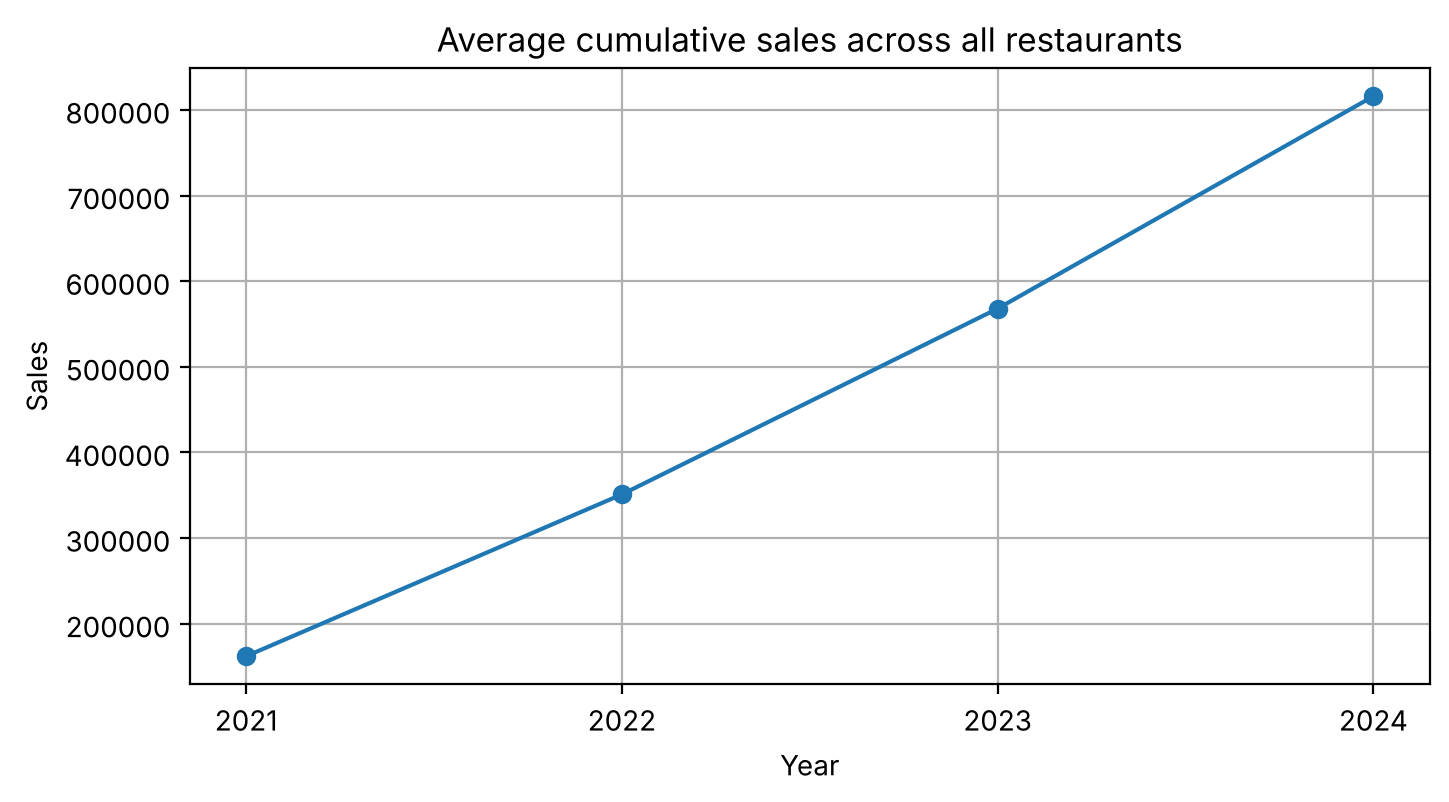

In [71]:
sales = np.array([[150000, 180000, 220000, 250000],
                  [120000, 140000, 160000, 190000],
                  [200000, 230000, 260000, 300000],
                  [180000, 210000, 240000, 270000],
                  [160000, 185000, 205000, 230000]])

cum = np.cumsum(sales, axis=1)          # cumulative per restaurant
avg_cum = cum.mean(axis=0)              # average over restaurants

plt.figure(figsize=(8, 4))
plt.plot([2021, 2022, 2023, 2024], avg_cum, marker="o")
plt.title("Average cumulative sales across all restaurants")
plt.xlabel("Year"); plt.ylabel("Sales"); plt.xticks([2021, 2022, 2023, 2024])
plt.grid(True); plt.show()

Q74 : <B>Normalize an array: min-max scaling and standardization (z-score).

**Answer:**

- **Min-max**: `(x - min) / (max - min)` -> range [0, 1].
- **Z-score**: `(x - mean) / std` -> mean 0, std 1.
Both are pure vectorized one-liners, commonly used in ML preprocessing.

In [72]:
x = np.array([10, 20, 30, 40, 50], dtype=float)

minmax = (x - x.min()) / (x.max() - x.min())
zscore = (x - x.mean()) / x.std()
print(minmax)
print(zscore.round(3), zscore.mean().round(6), zscore.std())

[0.   0.25 0.5  0.75 1.  ]
[-1.414 -0.707  0.     0.707  1.414] 0.0 0.9999999999999999


Q75 : <B>Detect and remove outliers from an array (IQR method).

**Answer:**

Compute Q1 and Q3, `IQR = Q3 - Q1`; values outside `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` are outliers. Filter with a Boolean mask.

In [73]:
data = np.array([12, 15, 14, 10, 13, 11, 16, 500, 12, -200])
q1, q3 = np.percentile(data, [25, 75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

print("bounds   :", low, high)
print("outliers :", data[(data < low) | (data > high)])
print("cleaned  :", data[(data >= low) & (data <= high)])

bounds   : 6.0 20.0
outliers : [ 500 -200]
cleaned  : [12 15 14 10 13 11 16 12]


Q76 : <B>Find the second largest element of an array.

**Answer:**

Get unique sorted values and pick the second last. (`np.unique` avoids confusion when the maximum is repeated.)

In [74]:
a = np.array([4, 9, 1, 9, 7, 3])
print(np.unique(a)[-2])             # 7
print(np.sort(a)[-2])               # 9 -> wrong if duplicates of max exist!

7


9


Q77 : <B>Create an 8x8 checkerboard pattern using NumPy.

**Answer:**

Start with zeros and set alternate positions to 1 using stepped slicing.

In [75]:
board = np.zeros((8, 8), dtype=int)
board[1::2, ::2] = 1
board[::2, 1::2] = 1
print(board)

[[0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]]


Q78 : <B>Compute a moving (rolling) average of window size 3.

**Answer:**

Convolve with a window of equal weights (`np.ones(k)/k`) using `mode='valid'` so only full windows are used.

In [76]:
data = np.array([10, 20, 30, 40, 50, 60, 70], dtype=float)
k = 3
print(np.convolve(data, np.ones(k) / k, mode="valid"))

[20. 30. 40. 50. 60.]


Q79 : <B>Matrix tasks: row sums, column sums, diagonal, trace and anti-diagonal.

**Answer:**

Use `sum(axis=...)`, `np.diag`, `np.trace`, and flip the matrix for the anti-diagonal.

In [77]:
m = np.arange(1, 10).reshape(3, 3)
print(m)
print("row sums  :", m.sum(axis=1))
print("col sums  :", m.sum(axis=0))
print("diagonal  :", np.diag(m))
print("trace     :", np.trace(m))
print("anti-diag :", np.diag(np.fliplr(m)))
print("upper tri :\n", np.triu(m))

[[1 2 3]
 [4 5 6]
 [7 8 9]]
row sums  : [ 6 15 24]
col sums  : [12 15 18]
diagonal  : [1 5 9]
trace     : 15
anti-diag : [3 5 7]
upper tri :
 [[1 2 3]
 [0 5 6]
 [0 0 9]]


Q80 : <B>Rotate or flip a matrix.

**Answer:**

`np.rot90(m, k)` rotates by 90° counter-clockwise k times; `np.flip(m, axis)`, `np.fliplr`, `np.flipud` mirror it.

In [78]:
m = np.array([[1, 2, 3],
              [4, 5, 6]])
print(np.rot90(m))
print(np.flip(m, axis=1))
print(np.flipud(m))

[[3 6]
 [2 5]
 [1 4]]
[[3 2 1]
 [6 5 4]]
[[4 5 6]
 [1 2 3]]


Q81 : <B>Find the common elements, and the elements present in only one of two arrays.

**Answer:**

Use `np.intersect1d` for common items and `np.setxor1d` for items present in only one of the arrays.

In [79]:
a = np.array([1, 2, 3, 4, 5, 6])
b = np.array([4, 5, 6, 7, 8])
print(np.intersect1d(a, b))
print(np.setxor1d(a, b))

[4 5 6]
[1 2 3 7 8]


Q82 : <B>Count and filter even/odd numbers; replace all odd numbers with -1.

**Answer:**

Use the modulo operator to build a mask; `np.where` for replacement without modifying the original.

In [80]:
a = np.arange(1, 16)
print("even:", a[a % 2 == 0], "count:", (a % 2 == 0).sum())
print("odd :", a[a % 2 == 1], "count:", (a % 2 == 1).sum())
print(np.where(a % 2 == 1, -1, a))

even: [ 2  4  6  8 10 12 14] count: 7
odd : [ 1  3  5  7  9 11 13 15] count: 8
[-1  2 -1  4 -1  6 -1  8 -1 10 -1 12 -1 14 -1]


Q83 : <B>Find the correlation between two variables.

**Answer:**

`np.corrcoef(x, y)` returns the correlation matrix; the off-diagonal element is Pearson's r (-1 to +1). `np.cov` gives covariance.

In [81]:
hours = np.array([1, 2, 3, 4, 5, 6])
marks = np.array([35, 45, 50, 65, 70, 85])
print(np.corrcoef(hours, marks).round(3))
print("r =", np.corrcoef(hours, marks)[0, 1].round(3))

[[1.   0.99]
 [0.99 1.  ]]
r = 0.99


Q84 : <B>Find the index of the maximum value in each row/column of a 2D array.

**Answer:**

`np.argmax(m, axis=1)` -> per row; `axis=0` -> per column. To get the position of the global max in 2D use `np.unravel_index(np.argmax(m), m.shape)`.

In [82]:
m = np.array([[3, 9, 2],
              [8, 1, 7],
              [4, 5, 6]])
print(np.argmax(m, axis=1))
print(np.argmax(m, axis=0))
print(np.unravel_index(np.argmax(m), m.shape))

[1 0 2]
[1 0 1]
(np.int64(0), np.int64(1))


Q85 : <B>Perform one-hot encoding of class labels using NumPy.

**Answer:**

Index an identity matrix with the label array - each label picks its own row.

In [83]:
labels = np.array([0, 2, 1, 2, 0])
print(np.eye(3, dtype=int)[labels])

[[1 0 0]
 [0 0 1]
 [0 1 0]
 [0 0 1]
 [1 0 0]]


Q86 : <B>Fit a straight line (simple linear regression) using NumPy.

**Answer:**

`np.polyfit(x, y, 1)` returns slope and intercept using least squares; alternatively solve using the normal equation / `np.linalg.lstsq`. Predictions = `slope * x + intercept`.

In [84]:
rng = np.random.default_rng(1)
x = np.arange(1, 11)
y = 3 * x + 5 + rng.normal(0, 1.5, size=10)

slope, intercept = np.polyfit(x, y, 1)
print(f"slope={slope:.2f}, intercept={intercept:.2f}")

# Same using least squares
X = np.column_stack((x, np.ones_like(x)))
w, *_ = np.linalg.lstsq(X, y, rcond=None)
print(w.round(2))

y_pred = slope * x + intercept
print("RMSE:", np.sqrt(np.mean((y - y_pred) ** 2)).round(3))

slope=2.99, intercept=5.37
[2.99 5.37]
RMSE: 0.944


Q87 : <B>Generate the first 10 multiples of 7 and the squares of numbers 1-10 without a loop.

**Answer:**

`np.arange` with a step, or arithmetic on `np.arange`.

In [85]:
print(np.arange(7, 71, 7))
print(np.arange(1, 11) ** 2)

[ 7 14 21 28 35 42 49 56 63 70]
[  1   4   9  16  25  36  49  64  81 100]


Q88 : <B>Swap two columns / rows of a matrix and reverse an array.

**Answer:**

Use fancy indexing with a list of indices in the new order.

In [86]:
m = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])
print(m[:, [2, 1, 0]])         # reverse column order
print(m[[1, 0, 2]])            # swap first two rows
print(np.arange(5)[::-1])      # reverse 1D

[[3 2 1]
 [6 5 4]
 [9 8 7]]
[[4 5 6]
 [1 2 3]
 [7 8 9]]
[4 3 2 1 0]


Q89 : <B>Apply a function along an axis. What does `np.apply_along_axis` do?

**Answer:**

It applies a function to 1D slices along a given axis. It is a convenience (loops internally); native aggregation with `axis=` is preferred when available.

In [87]:
m = np.array([[1, 2, 3], [4, 5, 6]])
print(np.apply_along_axis(lambda r: r.max() - r.min(), axis=1, arr=m))
print(np.ptp(m, axis=1))      # native equivalent

[2 2]
[2 2]


---
## 17. Tricky 'What is the Output?' Questions

Q90 : <B>Predict the output: `[1, 2, 3] * 2` versus `np.array([1, 2, 3]) * 2`.

**Answer:**

List -> `[1, 2, 3, 1, 2, 3]` (repetition). Array -> `[2 4 6]` (element-wise).

In [88]:
print([1, 2, 3] * 2)
print(np.array([1, 2, 3]) * 2)

[1, 2, 3, 1, 2, 3]
[2 4 6]


Q91 : <B>Predict the output: `np.array([1, 2, 3]) + [4, 5, 6]` and `np.array([1, 2, 3]) + 1`.

**Answer:**

Python lists are converted to arrays automatically -> `[5 7 9]`; scalar is broadcast -> `[2 3 4]`.

In [89]:
print(np.array([1, 2, 3]) + [4, 5, 6])
print(np.array([1, 2, 3]) + 1)

[5 7 9]
[2 3 4]


Q92 : <B>What is the output of `np.arange(10)[2:8:2]`, `np.arange(10)[-3:]` and `np.arange(10)[::-3]`?

**Answer:**

`[2 4 6]`, `[7 8 9]`, `[9 6 3 0]`.

In [90]:
a = np.arange(10)
print(a[2:8:2], a[-3:], a[::-3])

[2 4 6] [7 8 9] [9 6 3 0]


Q93 : <B>What is the result of `np.array([True, False, True]).sum()` and `np.array([1, 2, 3]) > 1`?

**Answer:**

`True` is treated as 1 -> sum is `2`. Comparison gives a Boolean array `[False True True]`.

In [91]:
print(np.array([True, False, True]).sum())
print(np.array([1, 2, 3]) > 1)

2
[False  True  True]


Q94 : <B>What is the shape after `np.zeros((3, 4)).sum(axis=0)`, `axis=1` and `np.zeros((3, 4))[:, 1]`?

**Answer:**

`(4,)`, `(3,)` and `(3,)`. Remember: the axis you sum over disappears. Indexing a single column with an integer also drops that dimension; use `[:, 1:2]` or `[:, [1]]` to keep it 2D.

In [92]:
z = np.zeros((3, 4))
print(z.sum(axis=0).shape, z.sum(axis=1).shape, z[:, 1].shape, z[:, 1:2].shape)

(4,) (3,) (3,) (3, 1)


Q95 : <B>Why does modifying a slice change the original array, but not a list slice?

**Answer:**

Python list slicing creates a **new list** (shallow copy), while NumPy basic slicing returns a **view** onto the same memory for efficiency. Use `.copy()` if you need independence.

In [93]:
lst = [1, 2, 3, 4]; l2 = lst[1:3]; l2[0] = 99
print("list  :", lst)

arr = np.array([1, 2, 3, 4]); a2 = arr[1:3]; a2[0] = 99
print("array :", arr)

list  : [1, 2, 3, 4]
array : [ 1 99  3  4]


Q96 : <B>What is the difference between `np.array([1, 2, 3])` shape `(3,)`, `(1, 3)` and `(3, 1)`?

**Answer:**

`(3,)` is a **1D** array (neither row nor column); `(1, 3)` is a 2D **row** vector; `(3, 1)` is a 2D **column** vector. They behave differently in broadcasting and matrix multiplication: `(3,1) + (1,3)` gives a `(3,3)` matrix.

In [94]:
v = np.array([1, 2, 3])
row = v.reshape(1, 3)
col = v.reshape(3, 1)
print(v.shape, row.shape, col.shape)
print(col + row)

(3,) (1, 3) (3, 1)
[[2 3 4]
 [3 4 5]
 [4 5 6]]


---
## 18. Comparison, Ecosystem and Project / HR Questions

Q97 : <B>What is the difference between NumPy and Pandas?

**Answer:**

| NumPy | Pandas |
|---|---|
| N-dimensional homogeneous arrays | `Series` / `DataFrame` - labelled, tabular, heterogeneous columns |
| Index by integer position | Index by labels **and** position |
| Best for numerical computation, linear algebra | Best for data cleaning, grouping, joins, time series, CSV/Excel |
| Faster for pure numeric work | Built **on top of** NumPy, adds convenience |

Q98 : <B>NumPy array vs Python list vs the `array` module?

**Answer:**

- **list** - flexible, mixed types, slow for math.
- **`array.array`** - compact typed 1D storage but no vectorized math, no N-D support.
- **NumPy array** - typed, N-D, vectorized, broadcasting, huge function library -> the standard for numerical work.

Q99 : <B>What are the limitations of NumPy and what are the alternatives for bigger or GPU workloads?

**Answer:**

NumPy is single-machine, in-memory and CPU-bound. Alternatives: **Dask** (out-of-core / parallel arrays), **CuPy** (NumPy API on GPU), **PyTorch / TensorFlow / JAX** (GPU + autograd), **Numba** (JIT-compile loops), **Pandas / Polars** for tabular data.

Q100 : <B>How would you debug a shape mismatch error?

**Answer:**

1. Print `.shape` and `.ndim` of every array involved.
2. Read the error message - it states both shapes.
3. Draw the shapes aligned from the right (broadcasting rules) or check `(m,n)@(n,p)` for matrix multiplication.
4. Fix with `reshape`, `np.newaxis`, `.T`, `np.squeeze`, or choose the correct `axis`.
5. Add `assert a.shape == (…)` checks in important code.

Q101 : <B>Tell me about your NumPy learning / project. (Sample answer - adapt it to yourself)

**Answer:**

> "I first learned Python fundamentals and then studied NumPy step by step: array creation, attributes and reshaping, then indexing, slicing, filtering and sorting, then merging and deleting data, and finally aggregations with `axis` and vector operations. I wrote my own notes in Jupyter and practised with a **restaurant sales dataset (Zomato-style)** with five restaurants across four years. I calculated total and average sales per restaurant, yearly totals, cumulative sales, identified the best performer and visualised the average cumulative sales using Matplotlib. This helped me understand `axis`, slicing 2D data and vectorized operations. I am now moving on to Pandas, and I'd like to apply these skills to real data-analysis work during the internship."

Tips: keep it 30-45 seconds, mention one concrete example, be honest about what you know, and end with your learning plan.

Q102 : <B>What would you learn after NumPy?

**Answer:**

**Pandas** (DataFrames, cleaning, groupby), **Matplotlib / Seaborn** (visualisation), basic **statistics**, then **scikit-learn** for machine learning and **SQL** for databases.

---
## 19. Rapid-Fire Cheat Sheet (Revise Before the Interview)

| Question | One-line answer |
|---|---|
| Full form of NumPy? | Numerical Python |
| Core object? | `ndarray` |
| Is NumPy array homogeneous? | Yes - one dtype |
| Default dtype of float? | `float64` |
| `arr.shape` vs `arr.size`? | Dimension lengths vs total number of elements |
| `arange` vs `linspace`? | Step size vs number of points |
| `flatten` vs `ravel`? | Copy vs view |
| Slicing returns? | View |
| Fancy / Boolean indexing returns? | Copy |
| `axis=0` means? | Collapse rows -> result per column |
| `axis=1` means? | Collapse columns -> result per row |
| `*` vs `@`? | Element-wise vs matrix multiplication |
| `np.where(cond)` returns? | Indices where True |
| `np.where(cond, x, y)` returns? | Element-wise if-else |
| Broadcasting rule? | Compare shapes from right; equal or 1 |
| `np.nan == np.nan`? | `False` -> use `np.isnan` |
| Copy an array? | `arr.copy()` |
| Sort descending? | `np.sort(a)[::-1]` |
| Remove duplicates? | `np.unique(a)` |
| Join arrays? | `concatenate`, `vstack`, `hstack`, `stack` |
| Set the seed? | `np.random.seed(n)` / `default_rng(n)` |
| Solve Ax=b? | `np.linalg.solve(A, b)` |
| Why NumPy is fast? | C code, contiguous memory, vectorization, no type checks |
| Compare floats? | `np.allclose` |
| Add a dimension? | `np.newaxis` / `expand_dims` |
| Reduce memory? | Smaller dtype (`int8`, `float32`) |

## Interview Tips
1. **Explain, then show** - give a definition, then a 2-line example.
2. **Know `axis`, broadcasting, copy vs view** - the three most-asked deep topics.
3. If you don't know something, say *"I haven't used that yet, but I would look in the NumPy docs (`help(np.func)`)"* - honesty beats guessing.
4. Mention **vectorization** whenever you are asked about performance.
5. Be ready to **write code on paper or on a shared screen** - practise typing the problems in Section 16 without looking.
6. Use `np.func?` / `help()` in Jupyter to explore any function quickly.

**Good luck!**